# Detecting AI-Generated Images — Multi-Branch Forensic Detector (GenImage-20K)

**Branches:** (A) frozen CLIP ViT-B/32, multi-layer features → (B) FFT spectrum CNN → (C) SRM + RGB-residual noise CNN → **gated fusion** → real / AI + **calibrated confidence**.

**Data:** `leatwitchy/genimage-20k-preprocessed` (19,802 images, 256×256 JPEG q85). Train 13,826 · validation 1,986 · seen test 1,990 · **Midjourney unseen test 2,000**.

### What this notebook adds over a plain "train and report accuracy" notebook
| # | Component | Why it matters |
|---|---|---|
| 1 | **Dataset shortcut audit** (metadata-only classifier, size-sliced metrics) | Real = JPEG / mostly 256–511 px, AI = PNG / often ≥512 px. Detectors can learn *file history*, not *generation artifacts*. |
| 2 | Spectral analysis (radial power profile, real vs. each generator) | Evidence for *why* the FFT branch should work. |
| 3 | GPU-side feature extraction (FFT, residual, CLIP resize) | Removes the CPU data-loader bottleneck on Kaggle. |
| 4 | Multi-layer CLIP CLS features, SRM filter bank + RGB residual | Stronger, more transferable inputs than the final CLIP layer / a plain blur residual. |
| 5 | Branch dropout + auxiliary per-branch heads | Stops the gate collapsing onto the easiest branch; each branch must learn something on its own. |
| 6 | Train-time degradations (JPEG, blur, down-up resize, noise) | Robustness. |
| 7 | OneCycle LR, grad clipping, AMP, early stopping on validation AUC | Stable training (the earlier run had a val-loss spike at epoch 4). |
| 8 | **Ablations** (CLIP / FFT / noise / FFT+noise / all) | Shows what fusion actually buys. |
| 9 | CLIP linear probe + **leave-one-generator-out** (cached features) | Cheap, honest cross-generator generalization estimate. |
| 10 | Robustness curves, temperature-scaling calibration, ECE | "Calibrated confidence" must be measured, not assumed. |
| 11 | **One-shot final test** behind a flag, per-generator and error analysis | Keeps seen/unseen tests uncontaminated. |
| 12 | Inference function + saved artifacts | Makes it a usable system. |

**Kaggle settings:** Accelerator → GPU, Internet → On (first CLIP download). Add the dataset via *Add Input*. Run top to bottom.
Keep `FINAL_EVAL = False` until every design choice is frozen.

## 0. Setup & configuration

In [7]:
# If the transformers import fails, run:  %pip install -q 'transformers>=4.45,<5' safetensors   (then restart)
import io, json, random, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter, ImageOps
from tqdm.auto import tqdm
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from transformers import CLIPVisionModel

from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                             f1_score, roc_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_everything()

ROOT = Path('/kaggle/input/datasets/leatwitchy/genimage-20k-preprocessed')
OUT = Path('/kaggle/working'); OUT.mkdir(parents=True, exist_ok=True)

CFG = dict(
    batch=32, epochs=6, patience=3, lr=3e-4, wd=1e-2,
    feat_dim=128, clip_id='openai/clip-vit-base-patch32', clip_layers=(4, 8, 12),
    aux_w=0.3,          # weight of auxiliary per-branch losses
    branch_drop=0.15,   # prob. of hiding a branch from the gate during training
    aug_p=0.5,          # prob. of applying train-time degradations
    workers=2,
)
RUN_ABLATIONS = False   # ~4 extra trainings (each about as long as the main run). Turn on once the main run works.
RUN_LOGO = True         # cheap: logistic regression on cached CLIP features
FINAL_EVAL = False      # TRUE ONLY ONCE, after all choices are frozen. Touches seen_test + Midjourney.

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
print('Device:', DEVICE, '| AMP:', USE_AMP)
if DEVICE.type != 'cuda':
    print('WARNING: no GPU. Enable it in Kaggle Settings -> Accelerator.')

Device: cuda | AMP: True


## 1. Data loading and integrity checks

In [8]:
df = pd.read_csv(ROOT / 'training_manifest.csv')
assert len(df) == 19802 and set(df['label'].unique()) == {0, 1}
rel = df['processed_file'].astype(str).str.replace('\\', '/', regex=False)
assert not rel.str.startswith('/').any() and not rel.str.contains(r'(^|/)\.\.(/|$)').any(), 'unsafe paths in manifest'
df['path'] = rel.map(lambda p: ROOT / p)
assert df['path'].map(lambda p: p.exists()).all(), 'Some processed images are missing'

# --- protocol checks -----------------------------------------------------------------------------
assert not (df.loc[df.split.isin(['train', 'validation', 'seen_test']), 'generator'] == 'midjourney').any(), 'Midjourney leaked!'
assert (df.loc[df.split == 'unseen_test', 'generator'] == 'midjourney').all()
split_hash = df.groupby('original_sha256')['split'].nunique()
assert (split_hash == 1).all(), 'Same source image appears in several splits'
df['matched'] = df['pair_native_bin_match'].astype(str).str.lower().isin(['true', '1'])

print(pd.crosstab(df['split'], df['label'], margins=True))
print()
print(pd.crosstab(df['generator'], df['split']))

tr = df[df.split == 'train'].reset_index(drop=True)
va = df[df.split == 'validation'].reset_index(drop=True)
print(f'\ntrain={len(tr)}  val={len(va)}  (seen_test / unseen_test stay untouched until FINAL_EVAL)')

label           0     1    All
split                         
seen_test     995   995   1990
train        6913  6913  13826
unseen_test  1000  1000   2000
validation    993   993   1986
All          9901  9901  19802

split                   seen_test  train  unseen_test  validation
generator                                                        
adm                           334   2304            0         330
glide                         332   2296            0         330
midjourney                      0      0         2000           0
stable_diffusion_v_1_4        332   2322            0         334
stable_diffusion_v_1_5        330   2308            0         332
vqdm                          330   2278            0         330
wukong                        332   2318            0         330

train=13826  val=1986  (seen_test / unseen_test stay untouched until FINAL_EVAL)


## 2. Exploratory analysis & **shortcut audit**

The processed images are all 256×256 JPEG q85, but the *originals* differ systematically (real = JPEG, mostly 256–511 px; AI = PNG, often ≥ 512 px).
If a model can predict the label from native size alone, then high accuracy may reflect *resampling history*, not generator fingerprints.
We therefore (a) fit a **metadata-only** classifier and (b) later report metrics **sliced by native-size bin**.

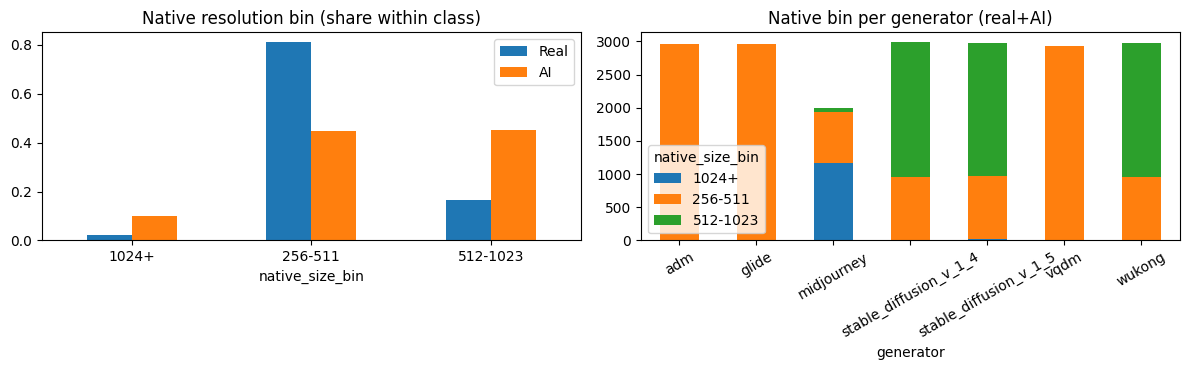

Metadata-only (native width/height) classifier, validation ROC-AUC = 1.000
-> Anything near 0.5 is ideal. The higher this is, the more a model can cheat via image size. Report this number next to your detector results.


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
pd.crosstab(df['native_size_bin'], df['label'], normalize='columns').plot.bar(ax=ax[0], rot=0)
ax[0].set_title('Native resolution bin (share within class)'); ax[0].legend(['Real', 'AI'])
pd.crosstab(df['generator'], df['native_size_bin']).plot.bar(stacked=True, ax=ax[1], rot=30)
ax[1].set_title('Native bin per generator (real+AI)')
plt.tight_layout(); plt.show()

def meta_features(d):
    w, h = d['native_width'].values.astype(float), d['native_height'].values.astype(float)
    return np.c_[np.log(w), np.log(h), np.log(w * h), w / h]

meta_clf = HistGradientBoostingClassifier(max_iter=200, random_state=SEED).fit(meta_features(tr), tr['label'])
meta_auc = roc_auc_score(va['label'], meta_clf.predict_proba(meta_features(va))[:, 1])
print(f'Metadata-only (native width/height) classifier, validation ROC-AUC = {meta_auc:.3f}')
print('-> Anything near 0.5 is ideal. The higher this is, the more a model can cheat via image size. '
      'Report this number next to your detector results.')

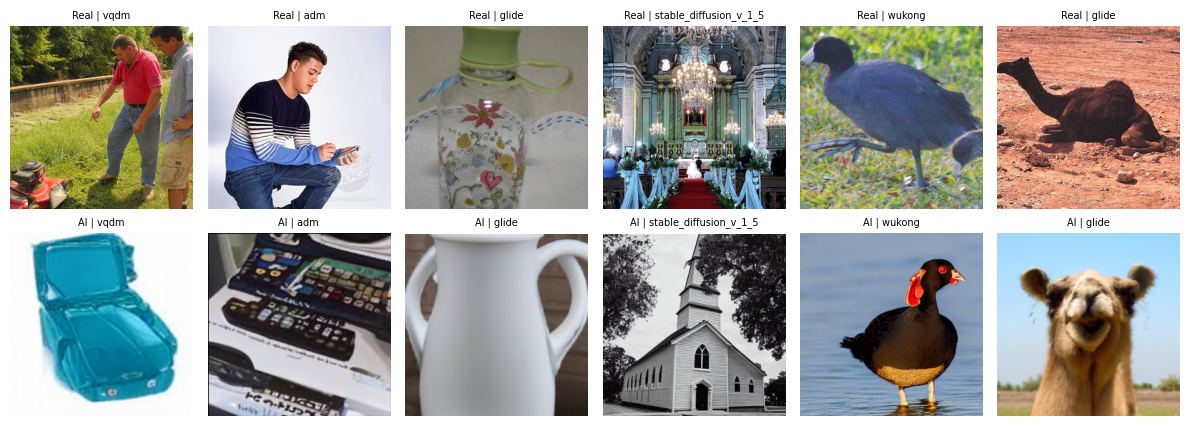

In [10]:
# --- sample grid ----------------------------------------------------------------------------------
def show_grid(rows, titles=None, ncols=6, size=2.0):
    n = len(rows); nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 1.1))
    axes = np.atleast_1d(axes).ravel()
    for a in axes: a.axis('off')
    for i, (_, r) in enumerate(rows.iterrows()):
        axes[i].imshow(Image.open(r['path']).convert('RGB'))
        t = titles[i] if titles is not None else f"{'AI' if r.label else 'Real'} | {r.generator}"
        axes[i].set_title(t, fontsize=7)
    plt.tight_layout(); plt.show()

sample = pd.concat([tr[tr.label == 0].sample(6, random_state=1), tr[tr.label == 1].sample(6, random_state=1)])
show_grid(sample)

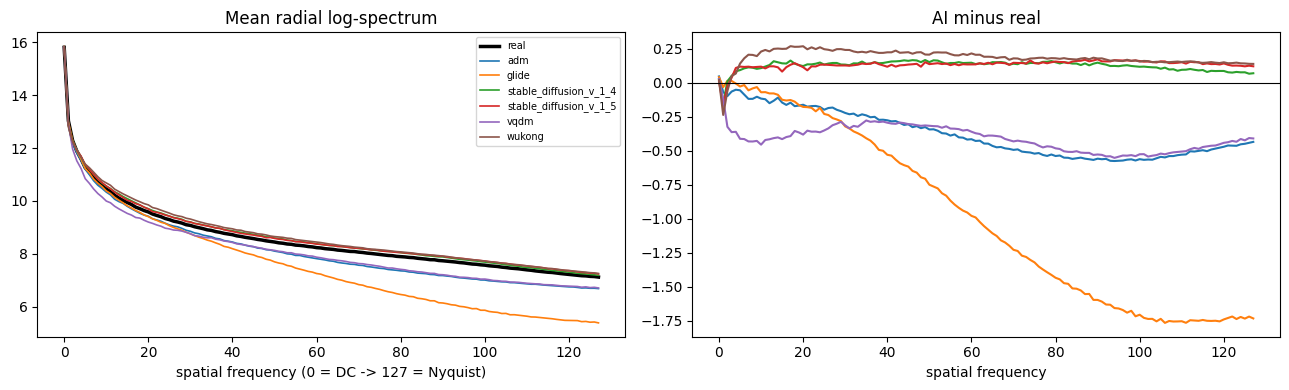

In [11]:
# --- radial (azimuthally averaged) log-power spectrum: real vs. each generator ----------------------
def radial_profile(path):
    g = np.asarray(Image.open(path).convert('L'), dtype=np.float32)
    p = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(g))))
    yy, xx = np.indices(p.shape); r = np.hypot(xx - p.shape[1] // 2, yy - p.shape[0] // 2).astype(int)
    return (np.bincount(r.ravel(), p.ravel()) / np.bincount(r.ravel()))[:128]

rng = np.random.RandomState(0)
prof = {}
real_rows = tr[tr.label == 0].sample(300, random_state=0)
prof['real'] = np.mean([radial_profile(p) for p in real_rows['path']], 0)
for g in sorted(tr.generator.unique()):
    rows = tr[(tr.generator == g) & (tr.label == 1)].sample(100, random_state=0)
    prof[g] = np.mean([radial_profile(p) for p in rows['path']], 0)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, v in prof.items():
    ax[0].plot(v, label=k, lw=2.5 if k == 'real' else 1.2, color='k' if k == 'real' else None)
    if k != 'real': ax[1].plot(v - prof['real'], label=k)
ax[0].set_title('Mean radial log-spectrum'); ax[0].set_xlabel('spatial frequency (0 = DC -> 127 = Nyquist)'); ax[0].legend(fontsize=7)
ax[1].axhline(0, color='k', lw=0.8); ax[1].set_title('AI minus real'); ax[1].set_xlabel('spatial frequency')
plt.tight_layout(); plt.show()

## 3. Degradations (used for training augmentation **and** robustness evaluation)

In [12]:
def jpeg_recompress(img, q):
    buf = io.BytesIO(); img.save(buf, 'JPEG', quality=int(q)); buf.seek(0)
    return Image.open(buf).convert('RGB')

def gaussian_blur(img, sigma):
    return img.filter(ImageFilter.GaussianBlur(sigma))

def down_up(img, f):
    w, h = img.size
    small = img.resize((max(8, int(w * f)), max(8, int(h * f))), Image.BICUBIC)
    return small.resize((w, h), Image.BICUBIC)

def add_noise(img, sigma):
    rng = np.random.default_rng(random.getrandbits(32))  # python `random` is re-seeded per DataLoader worker
    arr = np.asarray(img, dtype=np.float32) + rng.normal(0, sigma, (img.size[1], img.size[0], 3))
    return Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))

# fixed settings for evaluation
PERTURBATIONS = {
    'none':       None,
    'jpeg_q95':   lambda im: jpeg_recompress(im, 95),
    'jpeg_q75':   lambda im: jpeg_recompress(im, 75),
    'jpeg_q50':   lambda im: jpeg_recompress(im, 50),
    'blur_s1.0':  lambda im: gaussian_blur(im, 1.0),
    'blur_s2.0':  lambda im: gaussian_blur(im, 2.0),
    'downup_0.5': lambda im: down_up(im, 0.5),
    'noise_s5':   lambda im: add_noise(im, 5),
}

def train_augment(img):
    if random.random() < 0.5:
        img = ImageOps.mirror(img)
    if random.random() < CFG['aug_p']:
        for op in random.sample(['jpeg', 'blur', 'downup', 'noise'], k=random.choice([1, 2])):
            if op == 'jpeg':     img = jpeg_recompress(img, random.randint(60, 95))
            elif op == 'blur':   img = gaussian_blur(img, random.uniform(0.3, 1.5))
            elif op == 'downup': img = down_up(img, random.uniform(0.5, 0.9))
            else:                img = add_noise(img, random.uniform(1, 5))
    return img

## 4. Dataset (returns a `uint8` image only) and GPU-side views

The CLIP, FFT and residual views are all computed **on the GPU** from the same tensor. Workers only decode JPEGs, so loading is much faster.

In [13]:
class GenImageDS(Dataset):
    def __init__(self, table, train=False, perturb=None):
        self.table = table.reset_index(drop=True)
        self.train, self.perturb = train, perturb
        self.fn = PERTURBATIONS[perturb] if perturb else None
    def __len__(self):
        return len(self.table)
    def __getitem__(self, i):
        r = self.table.iloc[i]
        img = Image.open(r['path']).convert('RGB')
        if img.size != (256, 256):
            img = img.resize((256, 256), Image.LANCZOS)
        if self.train:
            img = train_augment(img)
        elif self.fn is not None:
            img = self.fn(img)
        x = torch.from_numpy(np.array(img)).permute(2, 0, 1).contiguous()  # uint8, 3x256x256
        return {'img': x, 'label': torch.tensor(int(r['label']), dtype=torch.float32)}

def make_loader(table, train=False, perturb=None, batch=None):
    return DataLoader(GenImageDS(table, train, perturb), batch_size=batch or (CFG['batch'] if train else 64),
                      shuffle=train, drop_last=train, num_workers=CFG['workers'],
                      pin_memory=(DEVICE.type == 'cuda'), persistent_workers=False)

CLIP_MEAN = torch.tensor([0.48145466, 0.4578275, 0.40821073]).view(1, 3, 1, 1)
CLIP_STD = torch.tensor([0.26862954, 0.26130258, 0.27577711]).view(1, 3, 1, 1)

def prepare_views(img_u8):
    # img_u8: B x 3 x 256 x 256 uint8 on the target device
    with torch.autocast(device_type=img_u8.device.type, enabled=False):
        x = img_u8.float() / 255.0
        clip = F.interpolate(x, size=(224, 224), mode='bicubic', align_corners=False, antialias=True).clamp(0, 1)
        clip = (clip - CLIP_MEAN.to(x.device)) / CLIP_STD.to(x.device)
        gray = 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]
        spec = torch.fft.fftshift(torch.fft.fft2(gray), dim=(-2, -1))
        fft = torch.log1p(spec.abs())
        fft = (fft - fft.mean((1, 2, 3), keepdim=True)) / fft.std((1, 2, 3), keepdim=True).clamp_min(1e-6)
        resid = (x - TF.gaussian_blur(x, [5, 5], [1.0, 1.0])) * 5.0
    return clip, fft, resid, gray

b = next(iter(make_loader(tr, train=True)))
print({k: (tuple(v.shape), v.dtype) for k, v in b.items()})
v = prepare_views(b['img'][:4].to(DEVICE))
print([tuple(t.shape) for t in v], '| all finite:', all(torch.isfinite(t).all().item() for t in v))

{'img': ((32, 3, 256, 256), torch.uint8), 'label': ((32,), torch.float32)}
[(4, 3, 224, 224), (4, 1, 256, 256), (4, 3, 256, 256), (4, 1, 256, 256)] | all finite: True


## 5. Model

* **CLIP branch** – frozen ViT-B/32; CLS token from layers 4, 8, 12 (early layers keep low-level cues that the last layer discards) → per-layer LayerNorm → MLP.
* **FFT branch** – CNN on the normalised log-magnitude spectrum.
* **Noise branch** – RGB high-pass residual **+ three fixed SRM filters** (steganalysis-style) → CNN.
* **Fusion** – a gate produces per-image softmax weights over the branch embeddings. During training each branch is randomly hidden from the gate (**branch dropout**) and every branch also has an **auxiliary classifier**.

The frozen CLIP is shared by reference (not registered as a submodule), so checkpoints stay small and ablations don't copy 350 MB each time.

In [14]:
print('Loading CLIP ...')
CLIP = CLIPVisionModel.from_pretrained(CFG['clip_id']).to(DEVICE).eval()
for p in CLIP.parameters():
    p.requires_grad_(False)

def build_srm():
    k1 = np.array([[0, 0, 0, 0, 0], [0, -1, 2, -1, 0], [0, 2, -4, 2, 0], [0, -1, 2, -1, 0], [0, 0, 0, 0, 0]], np.float32) / 4
    k2 = np.array([[-1, 2, -2, 2, -1], [2, -6, 8, -6, 2], [-2, 8, -12, 8, -2], [2, -6, 8, -6, 2], [-1, 2, -2, 2, -1]], np.float32) / 12
    k3 = np.zeros((5, 5), np.float32); k3[2, 1:4] = [1, -2, 1]; k3 /= 2
    return torch.tensor(np.stack([k1, k2, k3]))[:, None]  # 3 x 1 x 5 x 5

class ForensicCNN(nn.Module):
    def __init__(self, in_ch, feat=128):
        super().__init__()
        def block(i, o, pool=True):
            layers = [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.GELU(),
                      nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.GELU()]
            return nn.Sequential(*layers, nn.MaxPool2d(2)) if pool else nn.Sequential(*layers)
        self.stem = nn.BatchNorm2d(in_ch)
        self.body = nn.Sequential(block(in_ch, 32), block(32, 64), block(64, 128), block(128, 256, pool=False))
        self.head = nn.Sequential(nn.Linear(512, feat), nn.LayerNorm(feat))
    def forward(self, x):
        h = self.body(self.stem(x))
        h = torch.cat([F.adaptive_avg_pool2d(h, 1).flatten(1), F.adaptive_max_pool2d(h, 1).flatten(1)], 1)
        return self.head(h)

class CLIPBranch(nn.Module):
    def __init__(self, clip, layers, feat=128):
        super().__init__()
        self._clip = [clip]             # plain list -> NOT registered (frozen, shared, not saved in checkpoints)
        self.layers = tuple(layers)
        hid = clip.config.hidden_size
        self.norms = nn.ModuleList([nn.LayerNorm(hid) for _ in self.layers])
        self.proj = nn.Sequential(nn.Linear(hid * len(self.layers), feat), nn.GELU(),
                                  nn.Linear(feat, feat), nn.LayerNorm(feat))
    def raw_cls(self, clip_in):
        with torch.no_grad():
            hs = self._clip[0](pixel_values=clip_in, output_hidden_states=True).hidden_states
        return [hs[l][:, 0] for l in self.layers]
    def forward(self, clip_in):
        cls = self.raw_cls(clip_in)
        return self.proj(torch.cat([n(c.float()) for n, c in zip(self.norms, cls)], 1))

class MultiBranchDetector(nn.Module):
    def __init__(self, clip, branches=('clip', 'fft', 'noise'), feat=128, clip_layers=(4, 8, 12), branch_drop=0.15):
        super().__init__()
        self.branches, self.branch_drop = tuple(branches), branch_drop
        nb = len(self.branches)
        enc = {}
        if 'clip' in self.branches:  enc['clip'] = CLIPBranch(clip, clip_layers, feat)
        if 'fft' in self.branches:   enc['fft'] = ForensicCNN(1, feat)
        if 'noise' in self.branches: enc['noise'] = ForensicCNN(6, feat)   # 3 RGB residual + 3 SRM maps
        self.enc = nn.ModuleDict(enc)
        self.aux = nn.ModuleDict({k: nn.Linear(feat, 1) for k in enc})
        self.gate = nn.Sequential(nn.Linear(feat * nb, 128), nn.GELU(), nn.Linear(128, nb)) if nb > 1 else None
        self.cls = nn.Sequential(nn.Linear(feat, 64), nn.GELU(), nn.Dropout(0.2), nn.Linear(64, 1))
        self.register_buffer('srm', build_srm())

    def forward(self, img_u8):
        clip_in, fft, resid, gray = prepare_views(img_u8)
        feats = []
        for k in self.branches:
            if k == 'clip':    feats.append(self.enc['clip'](clip_in))
            elif k == 'fft':   feats.append(self.enc['fft'](fft))
            else:              feats.append(self.enc['noise'](torch.cat([resid, F.conv2d(gray, self.srm, padding=2)], 1)))
        Fs = torch.stack([f.float() for f in feats], 1)                    # B x nb x D
        B, nb, _ = Fs.shape
        aux = {k: self.aux[k](Fs[:, i]).squeeze(1) for i, k in enumerate(self.branches)}
        if nb == 1:
            w = torch.ones(B, 1, device=Fs.device)
        else:
            keep = torch.ones(B, nb, dtype=torch.bool, device=Fs.device)
            if self.training and self.branch_drop > 0:
                keep = torch.rand(B, nb, device=Fs.device) > self.branch_drop
                empty = ~keep.any(1)
                if empty.any():
                    rows = empty.nonzero().squeeze(1)
                    keep[rows] = False
                    keep[rows, torch.randint(0, nb, (len(rows),), device=Fs.device)] = True
            g = self.gate((Fs * keep.unsqueeze(-1)).flatten(1)).float().masked_fill(~keep, -1e4)
            w = torch.softmax(g, 1)
        fused = (w.unsqueeze(-1) * Fs).sum(1)
        return self.cls(fused).squeeze(1), w, aux

m = MultiBranchDetector(CLIP, branch_drop=CFG['branch_drop']).to(DEVICE)
print('Trainable parameters:', f"{sum(p.numel() for p in m.parameters() if p.requires_grad):,}")
m.eval()
with torch.no_grad():
    lg, w, ax_ = m(b['img'][:4].to(DEVICE))
assert lg.shape == (4,) and w.shape == (4, 3) and torch.allclose(w.sum(1), torch.ones(4, device=DEVICE), atol=1e-4)
print('PASS: forward OK | initial gate weights (clip, fft, noise):', w[0].tolist())
del m

Loading CLIP ...


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] CLIPVisionModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_at

Trainable parameters: 2,855,285


model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

PASS: forward OK | initial gate weights (clip, fft, noise): [0.34367501735687256, 0.40381962060928345, 0.252505362033844]


## 6. Metrics, prediction and training utilities

In [15]:
def sigmoid(z): return 1 / (1 + np.exp(-z))

def tpr_at_fpr(y, p, target=0.01):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.interp(target, fpr, tpr))

def compute_metrics(y, prob, thr=0.5):
    y = np.asarray(y); pred = (prob >= thr).astype(int)
    out = dict(n=len(y), acc=accuracy_score(y, pred), auc=np.nan, ap=np.nan, f1=f1_score(y, pred, zero_division=0),
               tpr_at_1pct_fpr=np.nan, real_acc=float((pred[y == 0] == 0).mean()) if (y == 0).any() else np.nan,
               ai_acc=float((pred[y == 1] == 1).mean()) if (y == 1).any() else np.nan)
    if len(np.unique(y)) == 2:
        out.update(auc=roc_auc_score(y, prob), ap=average_precision_score(y, prob), tpr_at_1pct_fpr=tpr_at_fpr(y, prob))
    return out

def ece_score(y, prob, bins=15):
    conf = np.maximum(prob, 1 - prob); correct = ((prob >= 0.5).astype(int) == y)
    edges = np.linspace(0.5, 1.0, bins + 1); e = 0.0
    for i, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
        m = (conf >= lo) & (conf <= hi) if i == 0 else (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(e)

@torch.no_grad()
def predict(model, table, perturb=None, desc=None):
    # returns logits (N,) and gate weights (N, n_branches), aligned with `table` row order
    model.eval(); L, W = [], []
    for bt in tqdm(make_loader(table, False, perturb), leave=False, desc=desc):
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
            lg, w, _ = model(bt['img'].to(DEVICE, non_blocking=True))
        L.append(lg.float().cpu()); W.append(w.float().cpu())
    return torch.cat(L).numpy(), torch.cat(W).numpy()

def compute_loss(logit, aux, y, aux_w):
    loss = F.binary_cross_entropy_with_logits(logit, y)
    if aux_w > 0 and len(aux) > 1:
        loss = loss + aux_w * sum(F.binary_cross_entropy_with_logits(a.float(), y) for a in aux.values()) / len(aux)
    return loss

def train_model(branches, epochs, tag):
    seed_everything()
    model = MultiBranchDetector(CLIP, branches, CFG['feat_dim'], CFG['clip_layers'], CFG['branch_drop']).to(DEVICE)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=CFG['lr'], weight_decay=CFG['wd'])
    loader = make_loader(tr, train=True)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG['lr'], total_steps=epochs * len(loader), pct_start=0.15)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    best_auc, best_state, bad, hist = -1.0, None, 0, []
    print(f'[{tag}] branches={branches} | trainable params={sum(p.numel() for p in params):,}')
    for ep in range(1, epochs + 1):
        model.train(); tot, n, t0 = 0.0, 0, time.time()
        for bt in tqdm(loader, desc=f'{tag} epoch {ep}/{epochs}', leave=False):
            x, y = bt['img'].to(DEVICE, non_blocking=True), bt['label'].to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                logit, _, aux = model(x)
            loss = compute_loss(logit.float(), aux, y, CFG['aux_w'])
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(y); n += len(y)
        lg, _ = predict(model, va)
        vm = compute_metrics(va['label'].values, sigmoid(lg))
        vloss = float(np.mean(np.logaddexp(0, lg) - va['label'].values * lg))
        hist.append(dict(epoch=ep, train_loss=tot / n, val_loss=vloss, val_acc=vm['acc'], val_auc=vm['auc'], val_f1=vm['f1']))
        print(f"[{tag}] ep{ep}: train={tot/n:.4f} val_loss={vloss:.4f} val_acc={vm['acc']:.4f} val_auc={vm['auc']:.4f} ({time.time()-t0:.0f}s)")
        if vm['auc'] > best_auc + 1e-4:
            best_auc, bad = vm['auc'], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG['patience']:
                print(f'[{tag}] early stop'); break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist)

## 7. Train the full three-branch model

[full] branches=('clip', 'fft', 'noise') | trainable params=2,855,285


full epoch 1/6:   0%|          | 0/432 [00:00<?, ?it/s]

  0%|          | 0/32 [00:00<?, ?it/s]

[full] ep1: train=0.6732 val_loss=0.2672 val_acc=0.8943 val_auc=0.9646 (561s)


full epoch 2/6:   0%|          | 0/432 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0c107ace00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0c107ace00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (12 outputs left out)

full epoch 6/6:   0%|          | 0/432 [00:00<?, ?it/s]

  0%|          | 0/32 [00:00<?, ?it/s]

[full] ep6: train=0.2980 val_loss=0.1493 val_acc=0.9491 val_auc=0.9885 (163s)


,epoch,train_loss,val_loss,val_acc,val_auc,val_f1
0,1,0.673203,0.267167,0.894260,0.964587,0.889822
1,2,0.494655,0.216976,0.912890,0.975539,0.910130
2,3,0.426347,0.174013,0.933535,0.983276,0.932722
3,4,0.380825,0.168337,0.944109,0.984901,0.943511
4,5,0.328356,0.149065,0.946123,0.988098,0.946527
5,6,0.297979,0.149289,0.949144,0.988469,0.949475


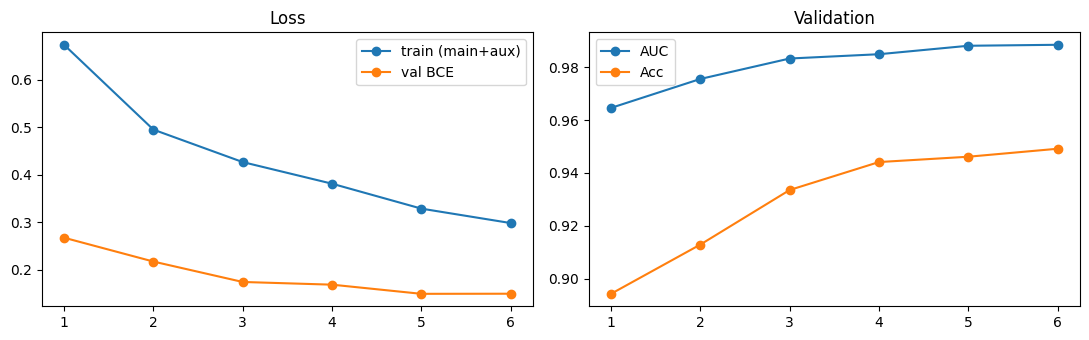

In [16]:
BRANCHES_FULL = ('clip', 'fft', 'noise')
model, hist = train_model(BRANCHES_FULL, CFG['epochs'], 'full')
hist.to_csv(OUT / 'training_history_full.csv', index=False)
display(hist)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(hist.epoch, hist.train_loss, 'o-', label='train (main+aux)'); ax[0].plot(hist.epoch, hist.val_loss, 'o-', label='val BCE'); ax[0].legend(); ax[0].set_title('Loss')
ax[1].plot(hist.epoch, hist.val_auc, 'o-', label='AUC'); ax[1].plot(hist.epoch, hist.val_acc, 'o-', label='Acc'); ax[1].legend(); ax[1].set_title('Validation')
plt.tight_layout(); plt.show()

## 8. Validation analysis: per generator, **per native-size bin**, gate weights

Per-bin AUC is the key shortcut test: inside one native-size bin the image size is no longer informative about the label.

  0%|          | 0/32 [00:00<?, ?it/s]

Overall validation: {'n': 1986.0, 'acc': 0.9491, 'auc': 0.9885, 'ap': 0.988, 'f1': 0.9495, 'tpr_at_1pct_fpr': 0.7905, 'real_acc': 0.9426, 'ai_acc': 0.9557}

Per generator (validation):


,n,acc,auc,real_acc,ai_acc
generator,,,,,
adm,330,0.9697,0.9978,0.9394,1.0000
glide,330,0.9667,0.9927,0.9636,0.9697
stable_diffusion_v_1_4,334,0.9641,0.9907,0.9641,0.9641
stable_diffusion_v_1_5,332,0.9458,0.9917,0.9337,0.9578
vqdm,330,0.9091,0.9679,0.9030,0.9152
wukong,330,0.9394,0.9872,0.9515,0.9273


Per native-size bin (validation):


,n,acc,auc,real_acc,ai_acc
native_size_bin,,,,,
1024+,10,1.0000,NaN,1.0000,NaN
256-511,1425,0.9495,0.9889,0.9430,0.9616
512-1023,551,0.9474,0.9838,0.9245,0.9498


Only pairs whose real/AI native bins match:
{'n': 1056.0, 'acc': 0.9517, 'auc': 0.9885, 'ap': 0.9874, 'f1': 0.9525, 'tpr_at_1pct_fpr': 0.7784, 'real_acc': 0.9356, 'ai_acc': 0.9678}


clip    fft  noise
label generator                                  
AI    adm                     0.098  0.051  0.851
      glide                   0.995  0.001  0.005
      stable_diffusion_v_1_4  0.996  0.001  0.004
      stable_diffusion_v_1_5  0.994  0.001  0.005
      vqdm                    0.996  0.001  0.004
      wukong                  0.992  0.001  0.007
Real  adm                     0.996  0.002  0.002
      glide                   0.997  0.001  0.002
      stable_diffusion_v_1_4  0.995  0.002  0.003
      stable_diffusion_v_1_5  0.995  0.001  0.004
      vqdm                    0.997  0.001  0.002
      wukong                  0.997  0.001  0.002

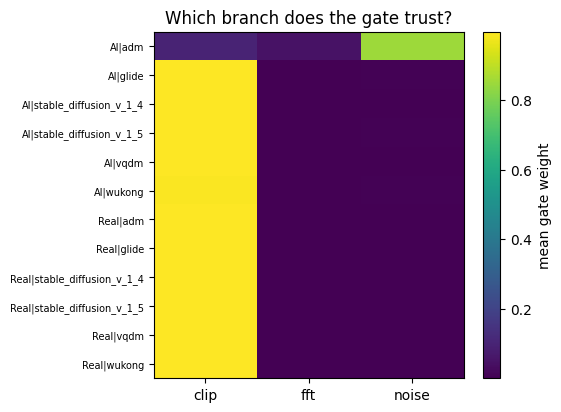

In [17]:
val_logits, val_w = predict(model, va)
yv = va['label'].values

def slice_report(table, prob, by):
    rows = []
    for k, d in table.groupby(by):
        idx = d.index.values
        rows.append(dict(**{by: k}, **compute_metrics(table.loc[idx, 'label'].values, prob[idx])))
    return pd.DataFrame(rows).set_index(by)

pv = sigmoid(val_logits)
print('Overall validation:', {k: round(float(v), 4) for k, v in compute_metrics(yv, pv).items()})
print('\nPer generator (validation):'); display(slice_report(va, pv, 'generator')[['n', 'acc', 'auc', 'real_acc', 'ai_acc']].round(4))
print('Per native-size bin (validation):'); display(slice_report(va, pv, 'native_size_bin')[['n', 'acc', 'auc', 'real_acc', 'ai_acc']].round(4))
print('Only pairs whose real/AI native bins match:'); print({k: round(float(v), 4) for k, v in compute_metrics(yv[va.matched.values], pv[va.matched.values]).items()})

gw = pd.DataFrame(val_w, columns=BRANCHES_FULL); gw['label'] = np.where(yv == 1, 'AI', 'Real'); gw['generator'] = va['generator'].values
gate_tab = gw.groupby(['label', 'generator'])[list(BRANCHES_FULL)].mean()
display(gate_tab.round(3))
plt.figure(figsize=(5, 4.5)); plt.imshow(gate_tab.values, cmap='viridis', aspect='auto')
plt.xticks(range(3), BRANCHES_FULL); plt.yticks(range(len(gate_tab)), [f'{a}|{b}' for a, b in gate_tab.index], fontsize=7)
plt.colorbar(label='mean gate weight'); plt.title('Which branch does the gate trust?'); plt.show()

## 9. Calibration — temperature scaling

Raw logits from a network are usually over-confident. We fit a single temperature **T on validation only** and report ECE before/after.
Note the limitation: T is fitted on *seen* generators, so confidence on *unseen* generators is expected to be less trustworthy — we measure that in the final evaluation instead of hiding it.

Temperature T = 1.353
ECE raw        : 0.0272
ECE calibrated : 0.0134


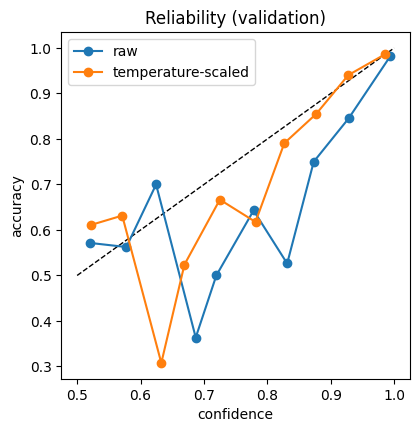

In [18]:
def fit_temperature(logits, y):
    z = torch.tensor(logits, dtype=torch.float32); t = torch.tensor(y, dtype=torch.float32)
    log_t = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)
    def closure():
        opt.zero_grad(); loss = F.binary_cross_entropy_with_logits(z / log_t.exp(), t); loss.backward(); return loss
    opt.step(closure)
    return float(log_t.exp())

def reliability(y, prob, bins=10, ax=None, label=None):
    conf = np.maximum(prob, 1 - prob); correct = ((prob >= 0.5).astype(int) == y)
    edges = np.linspace(0.5, 1, bins + 1); xs, ys = [], []
    for i, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
        m = (conf >= lo) & (conf <= hi) if i == 0 else (conf > lo) & (conf <= hi)
        if m.sum() >= 5: xs.append(conf[m].mean()); ys.append(correct[m].mean())
    ax.plot(xs, ys, 'o-', label=label)

T = fit_temperature(val_logits, yv)
THR = 0.5   # decision threshold on calibrated probability; chosen a priori (balanced classes)
print(f'Temperature T = {T:.3f}')
print(f'ECE raw        : {ece_score(yv, sigmoid(val_logits)):.4f}')
print(f'ECE calibrated : {ece_score(yv, sigmoid(val_logits / T)):.4f}')

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0.5, 1], [0.5, 1], 'k--', lw=1)
reliability(yv, sigmoid(val_logits), ax=ax, label='raw'); reliability(yv, sigmoid(val_logits / T), ax=ax, label='temperature-scaled')
ax.set_xlabel('confidence'); ax.set_ylabel('accuracy'); ax.set_title('Reliability (validation)'); ax.legend(); plt.show()

## 10. Robustness on **validation** (safe to look at — no test data touched)

If AUC collapses under mild JPEG or resizing, the model has learned fragile low-level cues. This is also the place to compare branches (see ablations).

none:   0%|          | 0/32 [00:00<?, ?it/s]

jpeg_q95:   0%|          | 0/32 [00:00<?, ?it/s]

jpeg_q75:   0%|          | 0/32 [00:00<?, ?it/s]

jpeg_q50:   0%|          | 0/32 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0c107ace00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
Exception ignored in: AssertionError: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0c107ace00>can only test a child process

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0c107ace00>
self._shutdown_workers()Traceback (most recent call last):

  File "/usr/local/lib/pyt

blur_s1.0:   0%|          | 0/32 [00:00<?, ?it/s]

blur_s2.0:   0%|          | 0/32 [00:00<?, ?it/s]

downup_0.5:   0%|          | 0/32 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0c107ace00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0c107ace00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a0c107ace00>    
self._shutdown_workers()
Traceback (most recent call last):
  File "/usr/local/lib/pyt

noise_s5:   0%|          | 0/32 [00:00<?, ?it/s]

,acc,auc,real_acc,ai_acc
perturbation,,,,
none,0.9491,0.9885,0.9426,0.9557
jpeg_q95,0.9320,0.9841,0.9577,0.9063
jpeg_q75,0.9149,0.9758,0.9507,0.8792
jpeg_q50,0.8968,0.9647,0.9476,0.8459
blur_s1.0,0.9169,0.9761,0.9003,0.9335
blur_s2.0,0.7800,0.9237,0.6093,0.9507
downup_0.5,0.9003,0.9688,0.8499,0.9507
noise_s5,0.9245,0.9784,0.9416,0.9074


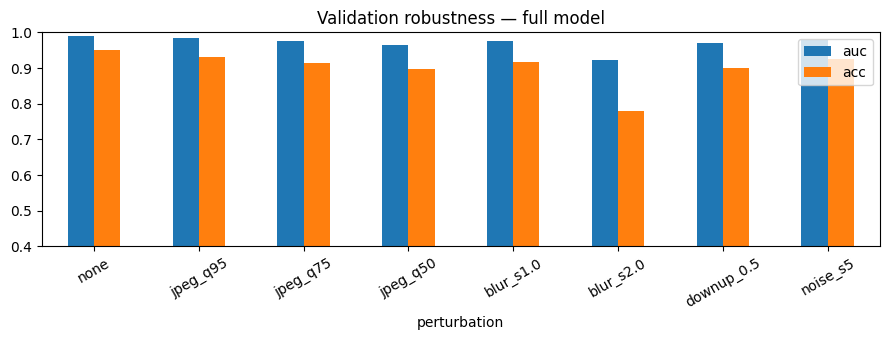

Watch real_acc vs ai_acc: a model that starts calling everything "AI" (or "real") after blur/JPEG is using a processing shortcut.


In [19]:
def robustness_table(mdl, table, names=None):
    rows = []
    for name in (names or PERTURBATIONS):
        lg, _ = predict(mdl, table, None if name == 'none' else name, desc=name)
        m = compute_metrics(table['label'].values, sigmoid(lg))
        rows.append(dict(perturbation=name, acc=m['acc'], auc=m['auc'], real_acc=m['real_acc'], ai_acc=m['ai_acc']))
    return pd.DataFrame(rows).set_index('perturbation')

rob_full = robustness_table(model, va)
display(rob_full.round(4))
rob_full[['auc', 'acc']].plot.bar(figsize=(9, 3.5), rot=30, ylim=(0.4, 1.0)); plt.title('Validation robustness — full model'); plt.tight_layout(); plt.show()
print('Watch real_acc vs ai_acc: a model that starts calling everything "AI" (or "real") after blur/JPEG is using a processing shortcut.')

## 11. CLIP linear probe + **leave-one-generator-out (LOGO)**

Cached frozen-CLIP features + logistic regression. It is cheap, a strong published baseline, and lets us ask: *if generator G was never seen, can a CLIP-based detector still catch it?*
(`unseen_test`/Midjourney is excluded from caching entirely.) Note: SD v1.4 and v1.5 are almost the same model, so leaving out one of them is an optimistic test.

In [20]:
@torch.no_grad()
def extract_clip_cache(table):
    probe = CLIPBranch(CLIP, CFG['clip_layers'], CFG['feat_dim']).to(DEVICE).eval()
    feats = []
    for bt in tqdm(make_loader(table, False, None, batch=128), desc='CLIP features'):
        clip_in, *_ = prepare_views(bt['img'].to(DEVICE))
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
            cls = probe.raw_cls(clip_in)
        feats.append(torch.cat([c.float() for c in cls], 1).cpu())
    return torch.cat(feats).numpy()

df_nm = df[df.split != 'unseen_test'].reset_index(drop=True)    # NO Midjourney
cache_path = OUT / 'clip_feats_no_midjourney.npy'
if cache_path.exists():
    X_all = np.load(cache_path)
else:
    X_all = extract_clip_cache(df_nm); np.save(cache_path, X_all)
assert len(X_all) == len(df_nm)
print('Cached features:', X_all.shape)

def fit_probe(mask_train):
    sc = StandardScaler().fit(X_all[mask_train])
    lr = LogisticRegression(C=0.05, max_iter=2000, n_jobs=-1).fit(sc.transform(X_all[mask_train]), df_nm.loc[mask_train, 'label'])
    return sc, lr

m_tr = (df_nm.split == 'train').values
sc, lr_clf = fit_probe(m_tr)
m_va = (df_nm.split == 'validation').values
p_probe = lr_clf.predict_proba(sc.transform(X_all[m_va]))[:, 1]
probe_val = compute_metrics(df_nm.loc[m_va, 'label'].values, p_probe)
print('CLIP linear probe, validation:', {k: round(float(v), 4) for k, v in probe_val.items()})

CLIP features:   0%|          | 0/140 [00:00<?, ?it/s]

Cached features: (17802, 2304)
CLIP linear probe, validation: {'n': 1986.0, 'acc': 0.9376, 'auc': 0.9858, 'ap': 0.9857, 'f1': 0.9374, 'tpr_at_1pct_fpr': 0.7432, 'real_acc': 0.9406, 'ai_acc': 0.9345}


,n,auc,acc,real_acc,ai_acc
held_out,,,,,
adm,2968,0.7855,0.6513,0.9468,0.3558
glide,2958,0.9512,0.8627,0.9466,0.7789
stable_diffusion_v_1_4,2988,0.9815,0.9354,0.9364,0.9344
stable_diffusion_v_1_5,2970,0.9853,0.9414,0.9428,0.9401
vqdm,2938,0.8086,0.6113,0.9632,0.2594
wukong,2980,0.9603,0.8842,0.9470,0.8215


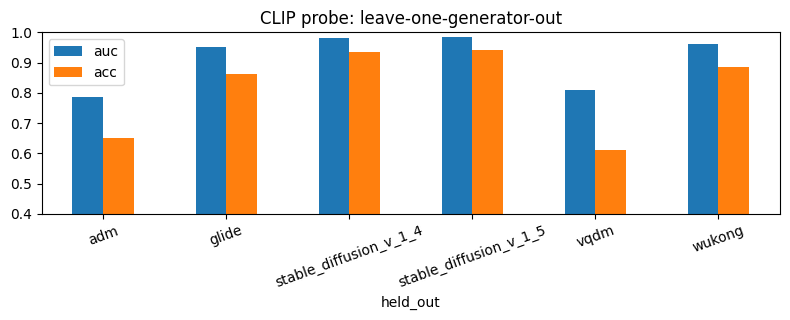

In [21]:
if RUN_LOGO:
    rows = []
    for g in sorted(df_nm.generator.unique()):
        m_train = ((df_nm.split == 'train') & (df_nm.generator != g)).values
        m_test = (df_nm.generator == g).values             # every split of the held-out generator
        sc_g, lr_g = fit_probe(m_train)
        p = lr_g.predict_proba(sc_g.transform(X_all[m_test]))[:, 1]
        m = compute_metrics(df_nm.loc[m_test, 'label'].values, p)
        rows.append(dict(held_out=g, n=m['n'], auc=m['auc'], acc=m['acc'], real_acc=m['real_acc'], ai_acc=m['ai_acc']))
    logo = pd.DataFrame(rows).set_index('held_out'); display(logo.round(4))
    logo[['auc', 'acc']].plot.bar(figsize=(8, 3.3), rot=20, ylim=(0.4, 1.0)); plt.title('CLIP probe: leave-one-generator-out'); plt.tight_layout(); plt.show()
    logo.to_csv(OUT / 'logo_clip_probe.csv')

## 12. Ablations (validation only)

Does fusion actually beat its parts? Each variant uses the same recipe, seed and epochs. Robustness columns show which branch breaks under JPEG / resizing.
Set `RUN_ABLATIONS = True` in the config cell to run (≈ 4 extra training runs).

In [22]:
ABL = {BRANCHES_FULL: model}
if RUN_ABLATIONS:
    for variant in [('clip',), ('fft',), ('noise',), ('fft', 'noise')]:
        ABL[variant], h = train_model(variant, CFG['epochs'], '+'.join(variant))
    rows = []
    for variant, mdl in ABL.items():
        r = {'branches': '+'.join(variant)}
        for name in ['none', 'jpeg_q75', 'blur_s1.0', 'downup_0.5']:
            lg, _ = predict(mdl, va, None if name == 'none' else name, desc=name)
            r[f'auc_{name}'] = compute_metrics(yv, sigmoid(lg))['auc']
        rows.append(r)
    abl_table = pd.DataFrame(rows).set_index('branches')
    abl_table.loc['CLIP linear probe (cached)', 'auc_none'] = probe_val['auc']
    display(abl_table.round(4)); abl_table.to_csv(OUT / 'ablation_validation.csv')
else:
    print('RUN_ABLATIONS = False -> skipped.')

RUN_ABLATIONS = False -> skipped.


## 13. Freeze everything — then the **one-shot** final evaluation

Before flipping `FINAL_EVAL = True`, write down (in your report) the chosen model, epochs, temperature `T` and threshold. After that, the seen test and the unseen Midjourney set are evaluated **once**; no further tuning on those numbers.

What is reported: overall + per-generator metrics, ROC, calibration (ECE before/after), **threshold-shift check** (accuracy at the pre-fixed threshold vs. the best possible threshold on the same set), size-sliced AUC, robustness on Midjourney, and the most confident mistakes.

In [23]:
def final_evaluation(mdl, T, thr, ablation_models=None):
    res, fig_roc = {}, plt.figure(figsize=(5.5, 5))
    plt.plot([0, 1], [0, 1], 'k--', lw=1)
    fpr, tpr, _ = roc_curve(yv, sigmoid(val_logits)); plt.plot(fpr, tpr, label=f'validation (AUC {roc_auc_score(yv, val_logits):.3f})')
    fig_rel, ax_rel = plt.subplots(figsize=(4.5, 4.5)); ax_rel.plot([0.5, 1], [0.5, 1], 'k--', lw=1)
    for name in ['seen_test', 'unseen_test']:
        t = df[df.split == name].reset_index(drop=True); y = t['label'].values
        lg, w = predict(mdl, t, desc=name)
        p_raw, p_cal = sigmoid(lg), sigmoid(lg / T)
        m = compute_metrics(y, p_cal, thr)
        # threshold-shift diagnostic
        ths = np.linspace(0.02, 0.98, 97); best_acc = max(accuracy_score(y, (p_cal >= th).astype(int)) for th in ths)
        m.update(ece_raw=ece_score(y, p_raw), ece_cal=ece_score(y, p_cal), best_possible_acc=best_acc,
                 mean_conf=float(np.maximum(p_cal, 1 - p_cal).mean()))
        res[name] = m
        print(f'\n=== {name} (n={len(t)}) ===')
        print({k: round(float(v), 4) for k, v in m.items()})
        print('Per generator:'); display(slice_report(t, p_cal, 'generator')[['n', 'acc', 'auc', 'real_acc', 'ai_acc']].round(4))
        print('Per native-size bin:'); display(slice_report(t, p_cal, 'native_size_bin')[['n', 'acc', 'auc', 'real_acc', 'ai_acc']].round(4))
        plt.figure(fig_roc.number); fpr, tpr, _ = roc_curve(y, p_cal); plt.plot(fpr, tpr, label=f'{name} (AUC {m["auc"]:.3f})')
        reliability(y, p_cal, ax=ax_rel, label=f'{name} (ECE {m["ece_cal"]:.3f})')
        # most confident mistakes
        wrong = np.where((p_cal >= thr).astype(int) != y)[0]
        if len(wrong):
            conf_wrong = np.maximum(p_cal, 1 - p_cal)[wrong]; top = wrong[np.argsort(-conf_wrong)[:12]]
            titles = [f"{'AI' if t.label[i] else 'Real'} -> pred {'AI' if p_cal[i] >= thr else 'Real'} ({max(p_cal[i], 1-p_cal[i]):.2f})\n{t.generator[i]} {t.native_width[i]}x{t.native_height[i]}" for i in top]
            print('Most confident errors:'); show_grid(t.iloc[top], titles=titles)
        t = t.assign(prob=p_cal); t.drop(columns=['path']).to_csv(OUT / f'predictions_{name}.csv', index=False)
    plt.figure(fig_roc.number); plt.xlabel('FPR'); plt.ylabel('TPR'); plt.legend(); plt.title('ROC'); plt.show()
    ax_rel.set_xlabel('confidence'); ax_rel.set_ylabel('accuracy'); ax_rel.legend(); ax_rel.set_title('Reliability on test sets'); plt.show()

    print('\nRobustness on held-out Midjourney (unseen generator):')
    t = df[df.split == 'unseen_test'].reset_index(drop=True)
    display(robustness_table(mdl, t, ['none', 'jpeg_q75', 'blur_s1.0', 'downup_0.5']).round(4))

    if ablation_models and len(ablation_models) > 1:
        rows = []
        for variant, am in ablation_models.items():
            r = {'branches': '+'.join(variant)}
            for name in ['seen_test', 'unseen_test']:
                tt = df[df.split == name].reset_index(drop=True); lg, _ = predict(am, tt, desc=name)
                mm = compute_metrics(tt['label'].values, sigmoid(lg / (T if variant == BRANCHES_FULL else 1.0)))
                r[f'{name}_auc'], r[f'{name}_acc'] = mm['auc'], mm['acc']
            rows.append(r)
        print('\nAblation on test sets (models chosen on validation):'); display(pd.DataFrame(rows).set_index('branches').round(4))
    return res

if FINAL_EVAL:
    final_results = final_evaluation(model, T, THR, ABL if RUN_ABLATIONS else None)
    with open(OUT / 'final_results.json', 'w') as f:
        json.dump({k: {a: float(b) for a, b in v.items()} for k, v in final_results.items()}, f, indent=2)
else:
    print('FINAL_EVAL = False -> seen_test and Midjourney remain untouched. Flip the flag ONCE when everything is frozen.')

FINAL_EVAL = False -> seen_test and Midjourney remain untouched. Flip the flag ONCE when everything is frozen.


## 14. Inference: image in → verdict, calibrated confidence, branch weights

New photos do not look like the training data, so images are first pushed through the *same* preprocessing as the dataset (center crop → Lanczos resize to 256 → JPEG q85).

truth: Real | glide


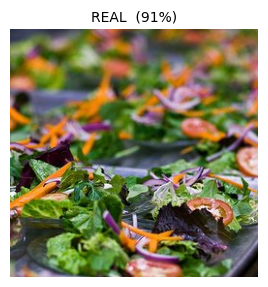

{'verdict': 'REAL', 'p_ai': 0.09032341837882996, 'confidence': 0.90967658162117, 'branch_weights': {'clip': 0.997, 'fft': 0.0, 'noise': 0.002}, 'branch_p_ai': {'clip': 0.108, 'fft': 0.646, 'noise': 0.286}}
truth: AI | glide


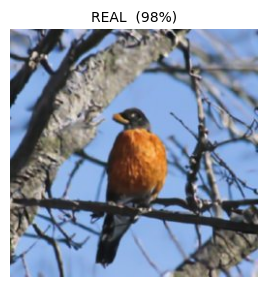

{'verdict': 'REAL', 'p_ai': 0.015626901760697365, 'confidence': 0.9843730982393026, 'branch_weights': {'clip': 0.998, 'fft': 0.0, 'noise': 0.002}, 'branch_p_ai': {'clip': 0.012, 'fft': 0.598, 'noise': 0.494}}
truth: Real | adm


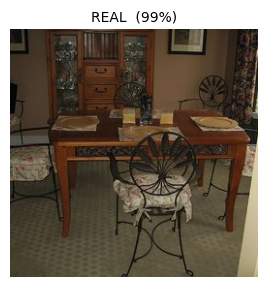

{'verdict': 'REAL', 'p_ai': 0.007876856252551079, 'confidence': 0.9921231437474489, 'branch_weights': {'clip': 0.997, 'fft': 0.0, 'noise': 0.002}, 'branch_p_ai': {'clip': 0.002, 'fft': 0.393, 'noise': 0.112}}
truth: AI | stable_diffusion_v_1_5


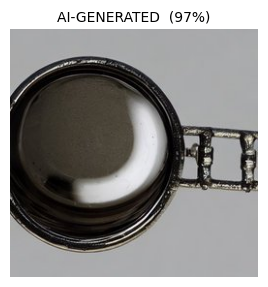

{'verdict': 'AI-GENERATED', 'p_ai': 0.9662626385688782, 'confidence': 0.9662626385688782, 'branch_weights': {'clip': 0.999, 'fft': 0.0, 'noise': 0.001}, 'branch_p_ai': {'clip': 0.991, 'fft': 0.356, 'noise': 0.171}}


In [24]:
def preprocess_like_dataset(img):
    img = img.convert('RGB'); w, h = img.size; s = min(w, h)
    img = img.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s)).resize((256, 256), Image.LANCZOS)
    return jpeg_recompress(img, 85)

@torch.no_grad()
def predict_image(path_or_img, mdl=None, T_=None, thr=None, show=True):
    mdl = mdl or model; T_ = T if T_ is None else T_; thr = THR if thr is None else thr
    img = Image.open(path_or_img) if isinstance(path_or_img, (str, Path)) else path_or_img
    img256 = preprocess_like_dataset(img)
    x = torch.from_numpy(np.array(img256)).permute(2, 0, 1).unsqueeze(0).to(DEVICE)
    mdl.eval()
    with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
        lg, w, aux = mdl(x)
    p_ai = float(torch.sigmoid(lg.float() / T_))
    out = dict(verdict='AI-GENERATED' if p_ai >= thr else 'REAL', p_ai=p_ai,
               confidence=max(p_ai, 1 - p_ai), branch_weights=dict(zip(mdl.branches, [round(float(v), 3) for v in w[0]])),
               branch_p_ai={k: round(float(torch.sigmoid(a.float())), 3) for k, a in aux.items()})
    if show:
        plt.figure(figsize=(3.2, 3.4)); plt.imshow(img256); plt.axis('off')
        plt.title(f"{out['verdict']}  ({out['confidence']:.0%})", fontsize=10); plt.show()
    return out

# demo on validation images (labels are known, so you can sanity-check)
for _, r in va.sample(4, random_state=3).iterrows():
    print('truth:', 'AI' if r.label else 'Real', '|', r.generator)
    print(predict_image(r['path']))

## 15. Save artifacts

In [25]:
ckpt = dict(state_dict={k: v.cpu() for k, v in model.state_dict().items()}, branches=BRANCHES_FULL, cfg=CFG,
            temperature=T, threshold=THR, val_metrics=compute_metrics(yv, sigmoid(val_logits / T), THR))
torch.save(ckpt, OUT / 'detector_full.pt')                       # CLIP weights are NOT stored; they are re-downloaded by name
pd.DataFrame([ckpt['val_metrics']]).to_csv(OUT / 'validation_metrics.csv', index=False)
rob_full.to_csv(OUT / 'robustness_validation.csv')

def load_detector(path=OUT / 'detector_full.pt'):
    ck = torch.load(path, map_location='cpu', weights_only=False)
    m = MultiBranchDetector(CLIP, ck['branches'], ck['cfg']['feat_dim'], ck['cfg']['clip_layers'], 0.0).to(DEVICE)
    m.load_state_dict(ck['state_dict']); return m.eval(), ck['temperature'], ck['threshold']

print('Saved to', OUT, ':', sorted(p.name for p in OUT.glob('*') if p.suffix in ('.pt', '.csv', '.json', '.npy')))

Saved to /kaggle/working : ['clip_feats_no_midjourney.npy', 'detector_full.pt', 'logo_clip_probe.csv', 'robustness_validation.csv', 'training_history_full.csv', 'validation_metrics.csv']


## 16. How to write this up honestly

**Claims you can make** (after the one-shot final evaluation): performance on seen generators; performance on held-out Midjourney; which branch contributes what (ablations); robustness to JPEG/blur/resize; calibration quality (ECE) on seen vs. unseen generators.

**Claims you should *not* make**
* "Detects any AI image" — you tested 7 generators, one unseen.
* "Learns generator fingerprints" — unless size-sliced AUC stays high and the metadata-only baseline (section 2) is near 0.5.
* "Calibrated" without stating *where* it was calibrated (seen generators) and the ECE on the unseen set.
* "Dataset is unbiased" — real images are JPEG-origin and smaller on average than AI images; resampling history is a known shortcut.

**Known limitations**
1. All images are 256×256 / JPEG q85; real-world images (WhatsApp compression, screenshots, filters) are out-of-distribution.
2. Frozen CLIP ViT-B/32 sees a 224×224 downsample; fine-grained cues are lost (try ViT-L/14 or patch-level features).
3. Single unseen generator (Midjourney, mostly 1024 px originals → heavy down-scaling) = one data point on generalization.
4. 20k images, one training seed. Re-run with 3 seeds and report mean ± std for a stronger claim.

**Extensions worth adding if time permits:** partial CLIP fine-tuning with LoRA · mixed-resolution training (patch crops at native scale) · Grad-CAM on the noise branch · test on a second dataset (e.g. different generators or in-the-wild images) · score-level ensembling vs. feature-level gating.